# Walmart Weekly Sales Prediction

**Goal:** Predict weekly sales for each Walmart store using past sales and economic features.

**Features (53):** holiday_flag, temperature, fuel_price, cpi, unemployment, year, month, week, lag_1 (previous week's sales for the same store), and 44 one-hot encoded store columns.

**Approach:**
1. Feature engineering: year, month, week, lag_1 (previous week's sales per store), one-hot encoded store
2. Time-based 80/20 split, no random shuffle, to avoid leakage
3. Models: Linear Regression (baseline), Random Forest, Tuned Random Forest (GridSearchCV + TimeSeriesSplit)

**Result:** Tuned Random Forest was best (R² = 0.975, RMSE ≈ 84.4k)

**Output:** Best model exported as `walmart_model.pkl` and used in a deployed web app.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/walmart_cleaned.csv')
df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [2]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store         6435 non-null   int64  
 1   date          6435 non-null   object 
 2   weekly_sales  6435 non-null   float64
 3   holiday_flag  6435 non-null   int64  
 4   temperature   6435 non-null   float64
 5   fuel_price    6435 non-null   float64
 6   cpi           6435 non-null   float64
 7   unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


,0
store,0
date,0
weekly_sales,0
holiday_flag,0
temperature,0
fuel_price,0
cpi,0
unemployment,0


In [3]:
df["date"] = pd.to_datetime(df["date"]) #Fixed date
df = df.sort_values(["store", "date"]).reset_index(drop=True) #store and date col are sorted and indexno reset. for lag col.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   store         6435 non-null   int64         
 1   date          6435 non-null   datetime64[ns]
 2   weekly_sales  6435 non-null   float64       
 3   holiday_flag  6435 non-null   int64         
 4   temperature   6435 non-null   float64       
 5   fuel_price    6435 non-null   float64       
 6   cpi           6435 non-null   float64       
 7   unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 402.3 KB


In [5]:
#extracting features year, month, and day.
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["week"] = df["date"].dt.isocalendar().week.astype(int)

df[["date", "year", "month", "week"]].head()

,date,year,month,week
0,2010-02-05,2010,2,5
1,2010-02-12,2010,2,6
2,2010-02-19,2010,2,7
3,2010-02-26,2010,2,8
4,2010-03-05,2010,3,9


In [6]:
# lag col = past sales used as an input feature to help predecting the future sales.
df["lag_1"] = df.groupby("store")["weekly_sales"].shift(1)

In [7]:
df = df.dropna().reset_index(drop=True)
df.shape

(6390, 12)

In [8]:
# One-hot encode store (done LAST, after lag features)
df_encoded = pd.get_dummies(df, columns=["store"], drop_first=True)
df_encoded.shape

(6390, 55)

In [9]:
df_encoded.head()

,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,week,...,store_36,store_37,store_38,store_39,store_40,store_41,store_42,store_43,store_44,store_45
0,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,6,...,False,False,False,False,False,False,False,False,False,False
1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,7,...,False,False,False,False,False,False,False,False,False,False
2,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,8,...,False,False,False,False,False,False,False,False,False,False
3,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,9,...,False,False,False,False,False,False,False,False,False,False
4,2010-03-12,1439541.59,0,57.79,2.667,211.380643,8.106,2010,3,10,...,False,False,False,False,False,False,False,False,False,False


In [10]:
# all columns except the target and date; this picks up store_2 ... store_45 automatically
features = []
for col in df_encoded.columns:
    if col not in ["weekly_sales", "date"]:
        features.append(col)

X = df_encoded[features]
y = df_encoded["weekly_sales"]

In [11]:
dates = np.sort(df_encoded["date"].unique())
cutoff = dates[int(len(dates) * 0.8)]

train = df_encoded[df_encoded["date"] < cutoff]
test = df_encoded[df_encoded["date"] >= cutoff]

X_train, y_train = train[features], train["weekly_sales"]
X_test, y_test = test[features], test["weekly_sales"]

print(X_train.shape, X_test.shape)

(5085, 53) (1305, 53)


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lr = LinearRegression()
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, pred_lr))
mae = mean_absolute_error(y_test, pred_lr)
r2 = r2_score(y_test, pred_lr)

print("Linear Regression")
print("RMSE:", round(rmse, 2))
print("MAE :", round(mae, 2))
print("R2  :", round(r2, 4))

Linear Regression
RMSE: 95351.67
MAE : 70229.08
R2  : 0.9681


In [13]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, pred_rf))
mae_rf = mean_absolute_error(y_test, pred_rf)
r2_rf = r2_score(y_test, pred_rf)

print("Random Forest")
print("RMSE:", round(rmse_rf, 2))
print("MAE :", round(mae_rf, 2))
print("R2  :", round(r2_rf, 4))

Random Forest
RMSE: 85230.81
MAE : 59303.15
R2  : 0.9745


In [14]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "RMSE": [rmse, rmse_rf],
    "MAE": [mae, mae_rf],
    "R2": [r2, r2_rf]
})
results

,Model,RMSE,MAE,R2
0,Linear Regression,95351.667394,70229.082966,0.968066
1,Random Forest,85230.808372,59303.149797,0.974485


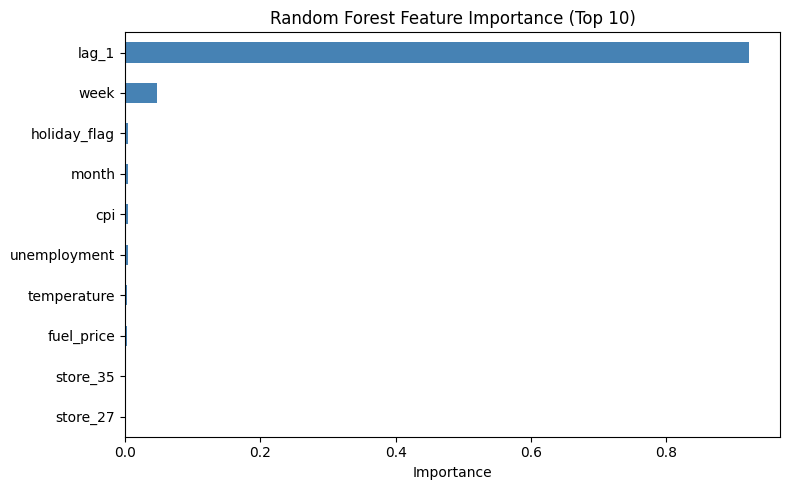

In [15]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

top10 = importances.tail(10)   # the 10 biggest (the series is sorted small to big)

plt.figure(figsize=(8, 5))
top10.plot(kind="barh", color="steelblue")
plt.title("Random Forest Feature Importance (Top 10)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

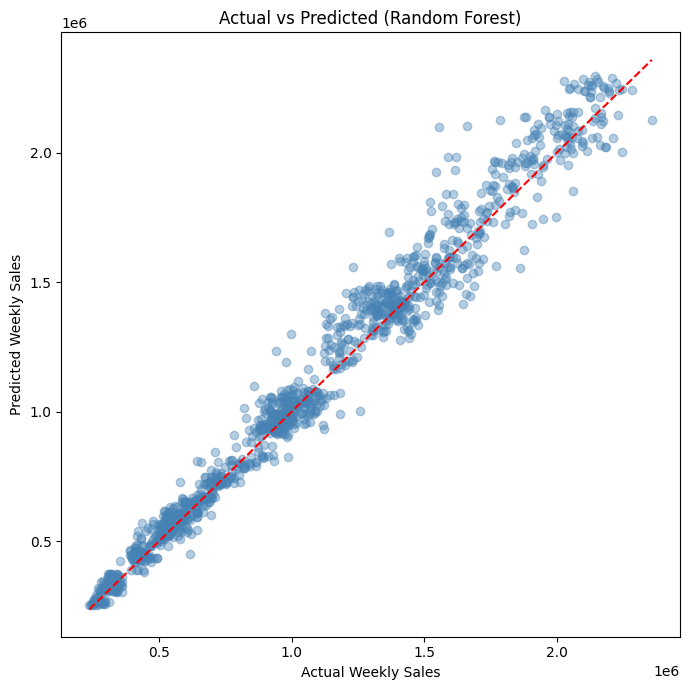

In [16]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred_rf, alpha=0.4, color="steelblue")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")
plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Actual vs Predicted (Random Forest)")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# train must be in date order for TimeSeriesSplit
train_sorted = train.sort_values("date")
X_tr = train_sorted[features]
y_tr = train_sorted["weekly_sales"]

grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid.fit(X_tr, y_tr)

print("Best parameters:", grid.best_params_)

Best parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [18]:
best_rf = grid.best_estimator_
pred_best = best_rf.predict(X_test)

rmse_best = np.sqrt(mean_squared_error(y_test, pred_best))
mae_best = mean_absolute_error(y_test, pred_best)
r2_best = r2_score(y_test, pred_best)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Tuned Random Forest"],
    "RMSE": [rmse, rmse_rf, rmse_best],
    "MAE": [mae, mae_rf, mae_best],
    "R2": [r2, r2_rf, r2_best]
})
results

,Model,RMSE,MAE,R2
0,Linear Regression,95351.667394,70229.082966,0.968066
1,Random Forest,85230.808372,59303.149797,0.974485
2,Tuned Random Forest,84418.079539,58832.886481,0.974970


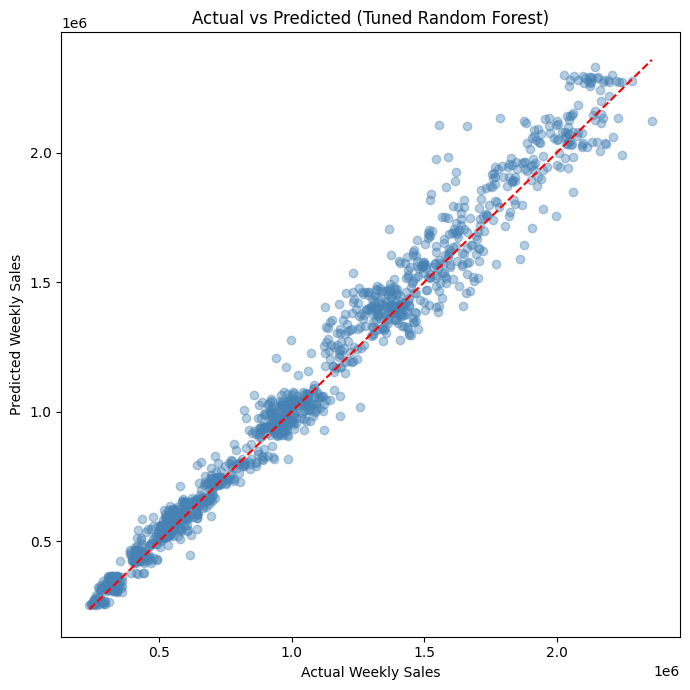

In [19]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, pred_best, alpha=0.4, color="steelblue")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")
plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")
plt.title("Actual vs Predicted (Tuned Random Forest)")
plt.tight_layout()
plt.show()

# Model Performance Summary

## 1. Approach
- **Target:** `weekly_sales`
- **Features (53):** holiday_flag, temperature, fuel_price, cpi, unemployment, year, month, week, lag_1 (previous week's sales for the same store), and 44 one-hot encoded store columns.
- **Split:** time-based 80/20 (5,085 training rows, 1,305 test rows). The model is trained on earlier weeks and tested on later weeks, which mimics real forecasting and avoids data leakage.
- **Models:** Linear Regression (baseline), Random Forest, and Random Forest tuned with GridSearchCV (TimeSeriesSplit, 3 folds).
- **Best parameters:** max_depth = 20, min_samples_leaf = 1, min_samples_split = 2, n_estimators = 200.

## 2. Model Comparison

| Model | RMSE | MAE | R² |
|---|---|---|---|
| Linear Regression | 95,352 | 70,229 | 0.9681 |
| Random Forest | 85,231 | 59,303 | 0.9745 |
| **Tuned Random Forest** | **84,418** | **58,833** | **0.9750** |

The **Tuned Random Forest** is the best model on all three metrics. Compared with the Linear Regression baseline, it reduces RMSE by about 11,000 and MAE by about 11,400. Hyperparameter tuning gave only a small extra gain over the default Random Forest (RMSE down by about 800), which means the default settings were already close to optimal.

## 3. Feature Importance
`lag_1` is by far the most important feature (about 92% of the total importance), followed by `week`. All other features, including the store columns, temperature, fuel price, CPI and unemployment, have very small importance. In other words, last week's sales are the strongest predictor of this week's sales, and the seasonal position in the year (week) adds a little more.

## 4. Business Interpretation
- The tuned model explains about 97.5% of the variation in weekly sales (R² = 0.975).
- Its average error (MAE) is about 58,800 per store per week. With average weekly sales of roughly 1.05 million, this is an error of about 5-6%.
- This accuracy is good enough to support weekly demand planning, such as inventory, staffing and budgeting for each store.
- Since `week` matters, seasonal patterns (especially around holidays) should be considered when planning stock and staff.

## 5. Limitations
- **Dependence on lag_1:** the model needs the previous week's actual sales, so it can only forecast one week ahead. Forecasting several weeks ahead would need a different approach.
- **Limited features:** no data on promotions, markdowns, store size or competitors. Economic variables (CPI, unemployment, fuel price) added very little predictive power.
- **Short time span:** the data covers about 143 weeks (2010-2012), so the test set is only around 29 weeks. Multi-year seasonality and long-term trends cannot be fully learned or verified.
- **Small tuning gain:** tuning improved the result only marginally, so further gains would more likely come from better features than from more tuning.


## 6. Conclusion
The Tuned Random Forest is the final model, with RMSE of about 84,418, MAE of about 58,833 and R² of about 0.975 on unseen future weeks. It outperforms the Linear Regression baseline and is suitable for short-term weekly sales forecasting.

In [20]:
import joblib

joblib.dump(best_rf, "walmart_model.pkl")

['walmart_model.pkl']